# Pergunta de pesquisa 1
---

Qual é a taxa de acerto ($Pass@1$, $T=0$) das LLMs na resolução textual dos problemas da OBI e como esse desempenho varia em relação aos diferentes níveis de dificuldade?

In [17]:
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path
import json
from codebleu import calc_codebleu

In [18]:
questions_path = []

path_database = Path('../database/dataset_obi_python/')

for path_question in path_database.glob("*"):
    if path_question.is_dir():
        questions_path.append(path_question)
        print(path_question.name)

problems = []

for question_path in questions_path:
    problems.append(json.loads(Path(question_path / "problem.json").read_text(encoding="utf-8")))

A Grande Casquinha
A idade de Dona Mônica
Alfabeto Alienígena
Altura da árvore
Amigos
Anagrama
Aplicativo de Calorias
Arara!
Arco e flecha
Arranha-céu
Atlanta
Atletismo
Avenida
Aventura na floresta mágica
Bactérias
Barcos da Nlogônia
Bibi e a árvore
Bits
Bondinho
Botas Trocadas
Burocracia
Busca na Internet
Cabo de Guerra
Cadeado
Cafeteria
Café com Leite
Caixinha de palitos
Calçada Imperial
Caminho
Camisetas da Olimpíada
Campeonato de Xadrez
Capital
Caravana
Cartas
Casamento de inteiros
Castelo de Blocos
Castelos da Nlogônia
Caverna de Ordinskaya
Chinelos
Chocolate em barra
Christina e os bombons
Chuva
Cinema
Cobra coral
Coleção de Upas
Concatena Dígitos
Concurso
Contas a Pagar
Conversa dos Pinguins
Copa do Mundo
Cubo Preto
Cálculo
Cálculo rápido
Câmeras
Código
Código de Compressão
Dança de Formatura
Dario e Xerxes
Decifra
Diagonal
Dieta
Direção
Distância entre amigos
Dividindo o império
Divisão do Tesouro
Doces da Estela
Dominó
Dominó Nlogônico
Dona Lesma
Dona Minhoca
Drone de Entrega


In [19]:
for question_path in questions_path:
    code_deepseek = Path("../results/dataset_obi_python/deepseek_deepseek-v4.1-flash/zero_shot/python/text/" + question_path.name + ".json")
    code_gemini = Path("../results/dataset_obi_python/gemini-3.8-flash/zero_shot/python/text/" + question_path.name + ".json")
    code_glm = Path("../results/dataset_obi_python/z-ai_glm-5.3-flash/zero_shot/python/text/" + question_path.name + ".json")
    
    if not code_deepseek.exists():
        print("[Deepseek]: " + question_path.name)
    if not code_gemini.exists():
            print("[Gemini]: " + question_path.name)
    if not code_glm.exists():
            print("[GLM]: " + question_path.name)
            

In [20]:
count_dificulty = {}

df_problems = pd.DataFrame(problems)

for level in df_problems["level"].unique():
    cases = df_problems[df_problems["level"] == level]
    count_dificulty[level] = len(cases)

In [21]:
print(count_dificulty)

{'pj': 93, 'p1': 47, 'p2': 57, 'senior': 17}


In [22]:
def read_csv(path: Path) -> pd.DataFrame:
    try:
        return pd.read_csv(path)
    except:
        return None

In [23]:
def count_ac_by_level(data: pd.DataFrame, predict_problems: pd.DataFrame) -> dict:
    
    name_by_level = {}
    
    for d in data.itertuples():
        if name_by_level.get(d.title):
            name_by_level[f"{d.title}_{d.year}"] = d.level
        else:
            name_by_level[d.title] = d.level
            
    counts = {}
    
    for level in data["level"].unique():
        counts[level] = 0
    
    
    for problem in predict_problems.itertuples():
        if problem.judge_predict == "AC":
            counts[name_by_level[problem.question_name]] += 1
        
    return counts

In [24]:
datas = []
datas.append(read_csv("../results/dataset_obi_python/judge/deepseek_deepseek-v4.1-flash.csv"))
datas.append(read_csv("../results/dataset_obi_python/judge/gemini-3.8-flash.csv"))
datas.append(read_csv("../results/dataset_obi_python/judge/z-ai_glm-5.3-flash.csv"))

results = []

for data in datas:
    results.append(count_ac_by_level(df_problems, data))

In [25]:
for data in datas:
    print(len(data))
    names = list(data["question_name"])
    names_aux = []
    for question_path in questions_path:
        if question_path.name in names_aux:
            print("Já existe o -> " + question_path.name)
        if not question_path.name in names:
            print(question_path.name)
        names_aux.append(question_path.name)

214
214
214


In [26]:
print(results)

[{'pj': 92, 'p1': 45, 'p2': 54, 'senior': 17}, {'pj': 91, 'p1': 45, 'p2': 57, 'senior': 17}, {'pj': 90, 'p1': 43, 'p2': 46, 'senior': 16}]


,LLM,PJ,P1,P2,Sênior,Geral
0,DeepSeek v4.1 Flash,98.92%,95.74%,94.74%,100.00%,97.20%
1,Gemini 3.8 Flash,97.85%,95.74%,100.00%,100.00%,98.13%
2,GLM 5.3 Flash,96.77%,91.49%,80.70%,94.12%,91.12%


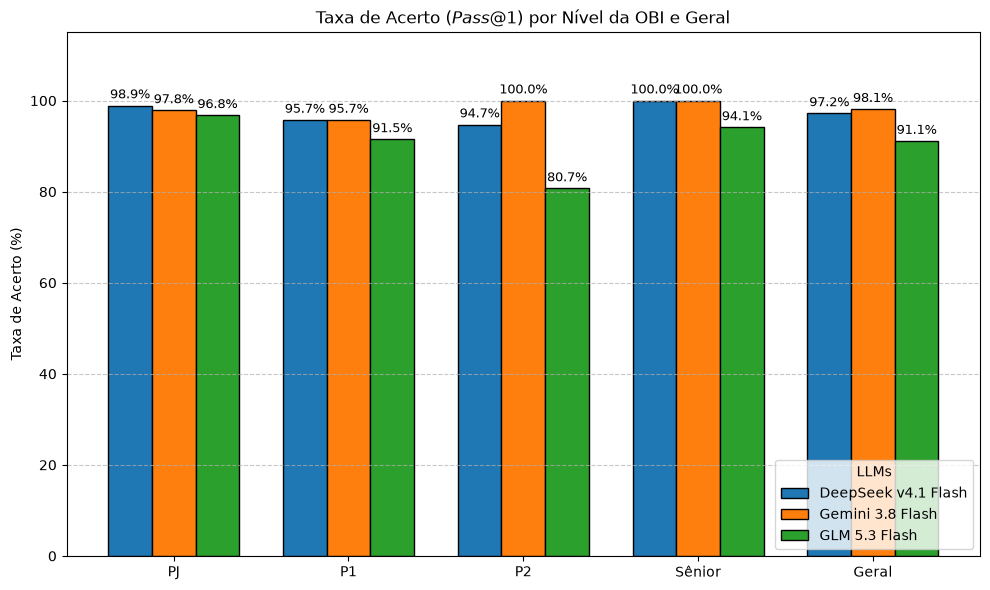

In [27]:
import numpy as np

# Nomes dos modelos avaliados correspondentes aos arquivos carregados
llm_names = ["DeepSeek v4.1 Flash", "Gemini 3.8 Flash", "GLM 5.3 Flash"]
if len(results) != len(llm_names):
    llm_names = [f"LLM {i+1}" for i in range(len(results))]

levels = ["pj", "p1", "p2", "senior"]
level_labels = ["PJ", "P1", "P2", "Sênior"]
categories = level_labels + ["Geral"]

total_problems = sum(count_dificulty.values())

# Cálculo das porcentagens de acerto (Pass@1)
pct_by_llm = []
data_rows = []

for name, res in zip(llm_names, results):
    pcts = [(res[lvl] / count_dificulty[lvl]) * 100 for lvl in levels]
    total_pct = (sum(res[lvl] for lvl in levels) / total_problems) * 100
    pcts.append(total_pct)
    pct_by_llm.append(pcts)
    
    row = {"LLM": name}
    for lvl_label, pct in zip(level_labels, pcts[:-1]):
        row[lvl_label] = f"{pct:.2f}%"
    row["Geral"] = f"{total_pct:.2f}%"
    data_rows.append(row)

# Tabela com as porcentagens
df_results_pct = pd.DataFrame(data_rows)
display(df_results_pct)

# Gráfico de barras agrupadas comparando as LLMs
x = np.arange(len(categories))
width = 0.25

fig, ax = plt.subplots(figsize=(10, 6))

for i, (name, pcts) in enumerate(zip(llm_names, pct_by_llm)):
    offset = (i - (len(llm_names) - 1) / 2) * width
    rects = ax.bar(x + offset, pcts, width, label=name, edgecolor="black")
    ax.bar_label(rects, fmt="%.1f%%", padding=3, fontsize=9)

ax.set_ylabel("Taxa de Acerto (%)")
ax.set_title("Taxa de Acerto ($Pass@1$) por Nível da OBI e Geral")
ax.set_xticks(x)
ax.set_xticklabels(categories)
ax.set_ylim(0, 115)
ax.legend(title="LLMs", loc="lower right")
ax.grid(axis="y", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()


In [28]:
def read_file(path: Path) -> str:
    if not path.exists():
        print(f"[Error]: file does not exist -> {path}")
        return None
    
    try:
        with open(path, "r", encoding="utf-8") as file:
            return file.read()
    except Exception as e:
        print(f"[Error]: could not read file -> {e}")
        return None


In [29]:
def read_code_json(path: Path) -> str:
    if not path.exists():
        print(f"[Error]: file does not exist -> {path}")
        return None
        
    try:
        data = json.loads(path.read_text(encoding="utf-8"))
        if isinstance(data, list) and len(data) > 0:
            return data[0].get("extracted_code")
        elif isinstance(data, dict):
            return data.get("extracted_code")
        return None
    except Exception as e:
        print(f"[Error]: could not read json -> {e}")
        return None


In [33]:
gabarito_python = read_file(Path("../database/dataset_obi_python/Arco e flecha/solutions/arco_paulo.py"))
llm_python = read_code_json(Path("../results/dataset_obi_python/gemini-3.8-flash/zero_shot/python/text/Arco e flecha.json"))

resultado = calc_codebleu(
    references=[[gabarito_python]],
    predictions=[llm_python],
    lang="python",
    weights=(0.25, 0.25, 0.25, 0.25)
)

print(f"CodeBLEU Total: {resultado['codebleu']:.4f}")
print(f"  - N-Gram Match:       {resultado['ngram_match_score']:.4f}")
print(f"  - Weighted N-Gram:    {resultado['weighted_ngram_match_score']:.4f}")
print(f"  - Syntax Match (AST): {resultado['syntax_match_score']:.4f}")
print(f"  - Dataflow Match:     {resultado['dataflow_match_score']:.4f}")

CodeBLEU Total: 0.1651
  - N-Gram Match:       0.0209
  - Weighted N-Gram:    0.0298
  - Syntax Match (AST): 0.3109
  - Dataflow Match:     0.2989


In [32]:
from code_bert_score import score

# Gabarito e Código da LLM
references = [
    read_file(Path("../database/dataset_obi_python/Arco e flecha/solutions/arco_paulo.py"))
]

predictions = [
    read_code_json(Path("../results/dataset_obi_python/gemini-3.8-flash/zero_shot/python/text/Arco e flecha.json"))
]

# O CodeBERTScore baixa automaticamente o modelo 'neulab/codebert-python' do HuggingFace
P, R, F1, F3 = score(cands=predictions, refs=references, lang="python")

print(f"Precision: {P.mean().item():.4f}")
print(f"Recall:    {R.mean().item():.4f}")
print(f"F1-Score:  {F1.mean().item():.4f}")
print(f"F3-Score:  {F3.mean().item():.4f}")  # F3 dá mais peso ao Recall

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 405.71it/s]


Precision: 0.7130
Recall:    0.7373
F1-Score:  0.7250
F3-Score:  0.7348
